### 使用 PyTorch RNN 实现正弦波预测
这个项目是学习 RNN 最合适的入门项目之一。我们不使用 LSTM、GRU 或 Transformer，只使用最基础的 nn.RNN，从数据生成、序列构造、模型定义、训练、验证到预测，完整走一遍深度学习项目流程。

通过这个项目，你需要真正理解：
1. 什么是时间序列数据（Time Series）。
2. 什么是时间步（Time Step）。
3. 什么是隐藏状态（Hidden State）。
4. RNN 如何利用历史信息预测未来。
5. 如何构造训练样本和标签。
6. 如何使用 PyTorch 训练 RNN。
7. 如何使用训练好的模型进行单步预测和连续多步预测。

In [70]:
import math

import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
import matplotlib.pyplot as plt
from torch.utils.data import TensorDataset, DataLoader, random_split
torch.manual_seed(23)

In [71]:
if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")
print(f"当前设备：{device}")

当前设备：mps


In [131]:
# 1、准备时间序列数据和标签
src_seqs = np.linspace(0, 10 * math.pi, 1000)
src_targets = np.array([round(math.sin(s), 4) for s in src_seqs])
print(src_seqs.shape, src_targets.shape)
print(src_seqs[:5], src_targets[:5])

(1000,) (1000,)
[0.         0.03144737 0.06289475 0.09434212 0.1257895 ] [0.     0.0314 0.0629 0.0942 0.1255]


/var/folders/62/z650ynp965s9rqn86r5kl6kr0000gn/T/ipykernel_45853/4172774102.py:7: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.figlegend()


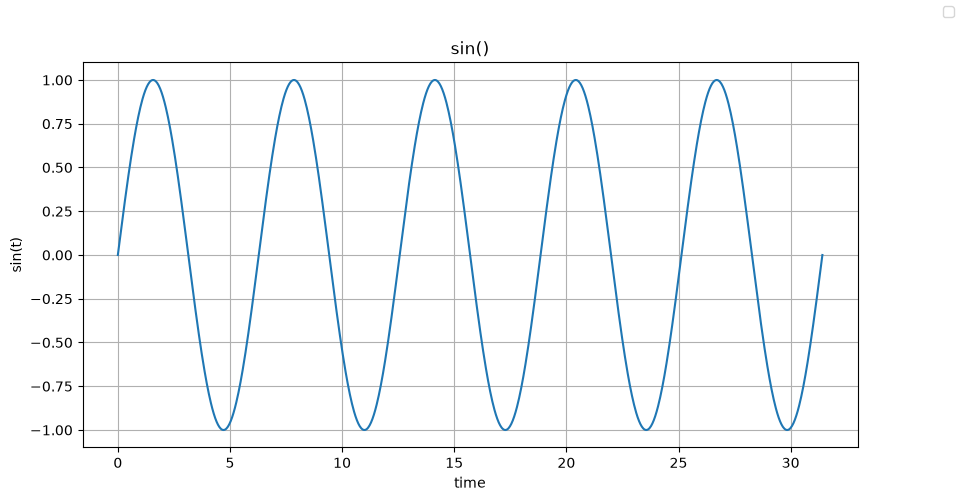

In [132]:
# 2、绘制正弦波
plt.figure(figsize=(10, 5))
plt.plot(src_seqs, src_targets)
plt.xlabel('time')
plt.ylabel('sin(t)')
plt.title("sin()")
plt.figlegend()
plt.grid(True)
plt.show()

In [133]:
# 3、将原始的 src_seqs 和 src_targets 转化为 模型输入数据
# 使用 seq_len = 10 的滑动窗口（Sliding Window） 来生成数据，每次向后滑动一个窗口来实现数据集构造
# 第一个时间点 [0, 9] --预测值---> 10 这个点
# 第二个时间点[1,10] --预测值---> 11 这个点
# 第三个时间点[2,11] --预测值---> 12 这个点
def create_seqences(data, seq_len = 10):
    """
    :param data: 原始的正弦波值
    :param seq_len: 每个样本时间长度
    :return:
    """

    # seq: 返回的数据是 [T, D] ，T表示时间步，D表示数据维度, T=10,D=1
    # target: 每个样本最后一个时间步下一个时间步的值
    seq = []
    target = []

    for i in range(0, len(data) - seq_len):
        seq.append(data[i:i + seq_len])
        target.append(data[i + seq_len])
    print(len(seq), len(target))

        # 转换成 Tensor
    X = torch.tensor(
        np.array(seq),
        dtype=torch.float32
    ).unsqueeze(-1)

    y = torch.tensor(
        np.array(target),
        dtype=torch.float32
    ).unsqueeze(-1)

    return X, y

seq, target = create_seqences(src_targets)
# torch.Size([990, 10, 1]) torch.Size([990, 1])
# 990 表示样本数量，10表示每个样本有10个时间点，1表示每个时间步只有一个特征，即正弦值
print(seq.shape, target.shape)
print(seq[:3])


990 990
torch.Size([990, 10, 1]) torch.Size([990, 1])
tensor([[[0.0000],
         [0.0314],
         [0.0629],
         [0.0942],
         [0.1255],
         [0.1566],
         [0.1876],
         [0.2184],
         [0.2489],
         [0.2793]],

        [[0.0314],
         [0.0629],
         [0.0942],
         [0.1255],
         [0.1566],
         [0.1876],
         [0.2184],
         [0.2489],
         [0.2793],
         [0.3093]],

        [[0.0629],
         [0.0942],
         [0.1255],
         [0.1566],
         [0.1876],
         [0.2184],
         [0.2489],
         [0.2793],
         [0.3093],
         [0.3391]]])


In [134]:
# 4、划分训练集和测试集
train_size = int(0.8 * len(seq))
# test_size = len(seq) - train_size
# random_split(seq, [train_size, test_size], generator=torch.Generator().manual_seed(23))
train_X_set = seq[:train_size]
train_y_set = target[:train_size]

test_X_set = seq[train_size:]
test_y_set = target[train_size:]

print(train_X_set.shape, train_y_set.shape)
print(test_X_set.shape, test_y_set.shape)


torch.Size([792, 10, 1]) torch.Size([792, 1])
torch.Size([198, 10, 1]) torch.Size([198, 1])


In [135]:
# 5、构造 dataloader

train_dataset = TensorDataset(train_X_set, train_y_set)
train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)

test_dataset = TensorDataset(test_X_set, test_y_set)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False)

tmpx, tmpy = next(iter(train_loader))
print(tmpx.shape, tmpy.shape)


torch.Size([64, 10, 1]) torch.Size([64, 1])


In [136]:
# 5、定义rnn模型
class SinRNN(nn.Module):
    def __init__(self, input_size=1, hidden_size=32, num_layers=1):
        super(SinRNN, self).__init__()
        self.rnn = nn.RNN(input_size, hidden_size, num_layers=num_layers, batch_first=True, nonlinearity="tanh")
        self.fc = nn.Linear(hidden_size, 1)
    def forward(self, x):
        # x: [N, T, 1]
        output, h_n = self.rnn(x)
        # 取最后一个时间步的输出
        last_output = output[:, -1, :]
        return self.fc(last_output)

# 批次为1，时间不长为5，每个时间点有10个样本
tmp_x = torch.randn(64, 10, 1)
tmp_model = SinRNN(input_size=1, hidden_size=32, num_layers=1)
res = tmp_model(tmp_x)
print(res.shape)
print(res.detach().numpy())

torch.Size([64, 1])
[[-0.19807807]
 [-0.33243734]
 [-0.1274074 ]
 [-0.11898076]
 [-0.18326303]
 [-0.2552585 ]
 [-0.31568107]
 [-0.04940876]
 [-0.27664968]
 [-0.08519249]
 [-0.13097763]
 [-0.06967735]
 [-0.24148986]
 [-0.21193811]
 [-0.28117985]
 [-0.1282165 ]
 [-0.19440082]
 [-0.24191615]
 [-0.13605008]
 [-0.13395625]
 [-0.26638934]
 [-0.11708742]
 [-0.11982567]
 [-0.1289359 ]
 [-0.14791104]
 [-0.2101286 ]
 [-0.03755387]
 [-0.20765054]
 [-0.26458308]
 [-0.18099424]
 [-0.27395433]
 [-0.17690486]
 [-0.09798076]
 [-0.07366892]
 [-0.10205626]
 [-0.19609597]
 [-0.19712186]
 [-0.23145327]
 [-0.0906876 ]
 [-0.21717817]
 [-0.30851015]
 [-0.06919806]
 [-0.24283987]
 [-0.18173605]
 [-0.14470321]
 [-0.23331854]
 [-0.12921765]
 [-0.135066  ]
 [-0.12788472]
 [-0.21584412]
 [-0.1304897 ]
 [-0.15624404]
 [-0.3096423 ]
 [-0.16641513]
 [-0.25221506]
 [-0.06161832]
 [ 0.00524267]
 [-0.08337351]
 [-0.21290323]
 [-0.27034825]
 [-0.14118358]
 [ 0.01100584]
 [-0.22998646]
 [-0.10598121]]


In [141]:
# 6、训练 SinRNN

model = SinRNN().to(device)
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=30, gamma=0.1)
epochs = 100

losses = []

for epoch in range(epochs):
    model.train()
    train_loss_sum = 0
    train_samples = 0
    for X, y in train_loader:
        X, y = X.to(device), y.to(device)
        optimizer.zero_grad(set_to_none=True)
        output = model(X)
        loss = criterion(output, y)
        loss.backward()
        optimizer.step()

        size = X.shape[0]
        train_samples += size
        train_loss_sum += loss.item() * size

    loss = train_loss_sum / train_samples
    losses.append(loss)

    scheduler.step()

    lr = scheduler.get_last_lr()[0]

    if (epoch + 1) % 10 == 0:
        print(
            f"Epoch [{epoch + 1}/{epochs}], "
            f"LR: {lr:.6f}, "
            f"Loss: {loss:.6f}"
        )

# 保存模型
torch.save(model.state_dict(), "../../data/output/SinRNN_model_state_dict.pth")
print("模型保存成功")


Epoch [10/100], LR: 0.001000, Loss: 0.004089
Epoch [20/100], LR: 0.001000, Loss: 0.000814
Epoch [30/100], LR: 0.000100, Loss: 0.000726
Epoch [40/100], LR: 0.000100, Loss: 0.000572
Epoch [50/100], LR: 0.000100, Loss: 0.000558
Epoch [60/100], LR: 0.000010, Loss: 0.000547
Epoch [70/100], LR: 0.000010, Loss: 0.000537
Epoch [80/100], LR: 0.000010, Loss: 0.000535
Epoch [90/100], LR: 0.000001, Loss: 0.000534
Epoch [100/100], LR: 0.000001, Loss: 0.000533
模型保存成功


In [142]:
# 测试
def evaluate(model, test_loader) -> (torch.Tensor, torch.Tensor):
    model.eval()
    test_y = []
    pred_y = []
    with torch.no_grad():
        test_loss = 0
        test_samples = 0
        for X, y in test_loader:
            X, y = X.to(device), y.to(device)
            pred = model(X)
            test_samples += y.shape[0]
            test_loss += F.mse_loss(pred, y, reduction="sum").item()

            test_y.append(y.cpu())
            pred_y.append(pred.cpu())

        loss = test_loss / test_samples
        print(f"测试总损失：{loss:.6f}")
        return test_y, pred_y

test_y, pred_y = evaluate(model, test_loader)

测试总损失：0.000532


torch.Size([64, 1]) torch.Size([64, 1])
<class 'torch.Tensor'>
torch.Size([64])
tensor([0.0879, 0.1192, 0.1504, 0.1814, 0.2122, 0.2428, 0.2732, 0.3033, 0.3331,
        0.3626, 0.3917, 0.4205, 0.4488, 0.4767, 0.5041, 0.5310, 0.5574, 0.5832,
        0.6084, 0.6331, 0.6571, 0.6805, 0.7032, 0.7252, 0.7465, 0.7671, 0.7868,
        0.8059, 0.8241, 0.8415, 0.8581, 0.8738, 0.8886, 0.9026, 0.9157, 0.9279,
        0.9392, 0.9495, 0.9589, 0.9673, 0.9748, 0.9814, 0.9869, 0.9915, 0.9951,
        0.9977, 0.9993, 1.0000, 0.9996, 0.9983, 0.9960, 0.9927, 0.9884, 0.9831,
        0.9769, 0.9697, 0.9615, 0.9524, 0.9424, 0.9314, 0.9195, 0.9066, 0.8929,
        0.8783])


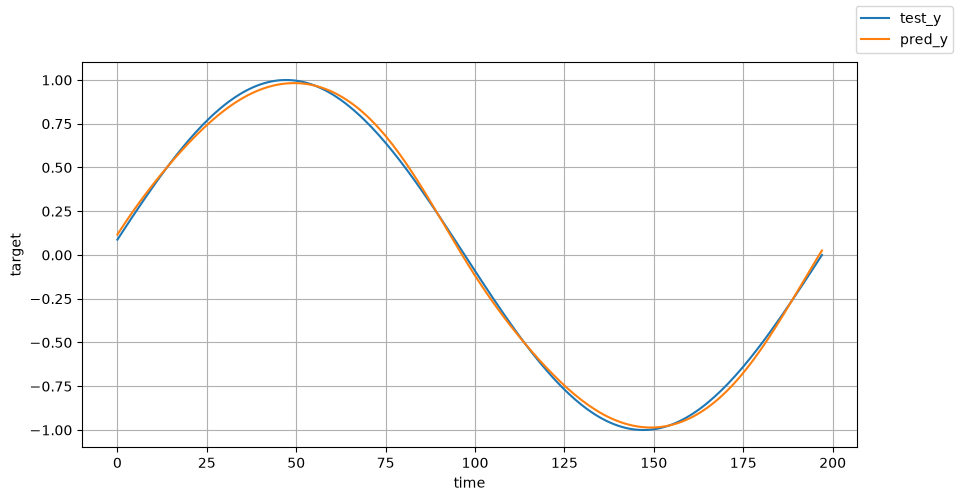

In [143]:
# 绘制真实值与预测值的差距


print(test_y[0].shape, pred_y[0].shape)
print(type(test_y[0]))
print(test_y[0].squeeze(1).shape)
print(test_y[0].squeeze(1))

test_y_list, pred_y_list = [], []

for tx, py in zip(test_y, pred_y):
    test_y_list.append(tx.squeeze(1).numpy().tolist())
    pred_y_list.append(py.squeeze(1).numpy().tolist())
test_y_list = [x for sublist in test_y_list for x in sublist]
pred_y_list = [x for sublist in pred_y_list for x in sublist]


plt.figure(figsize=(10, 5))
plt.plot(np.array(test_y_list), label="test_y")
plt.plot(np.array(pred_y_list), label="pred_y")
plt.xlabel("time")
plt.ylabel("target")
plt.figlegend()
plt.grid(True)
plt.show()
